**Step 1: Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

**Step 2: Load the Dataset**

In [2]:
df = pd.read_excel('Data/Online-Retail.xlsx')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Step 3: Data Preprocessing**

In [4]:
df.dropna(inplace=True)
df['InvoiceData'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df = df[df['Quantity'] > 0]

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceData,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01 08:26:00,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01 08:26:00,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01 08:26:00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01 08:26:00,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01 08:26:00,20.34


**Step 4: Feature Engineering**

In [6]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days = 1)
rfm = df.groupby('CustomerID').agg({
     'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique', 
    'TotalPrice': 'sum' 
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [7]:
X = rfm[['Recency', 'Frequency', 'Monetary']]
y = np.where(rfm['Monetary'] > rfm['Monetary'].median(), 1, 0)
X_train,X_test,y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [8]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((3471, 3), (868, 3), (3471,), (868,))

**Step 6: Train the CatBoost Model**

In [9]:
model = CatBoostClassifier(iterations=100, learning_rate=0.1, depth=6, verbose=False)
model.fit(X_train, y_train)
accuracy = model.score(X_test, y_test)
print(f'Accuracy:{accuracy:.2f}')

Accuracy:1.00


**Step 7: Visualize Feature Importance**

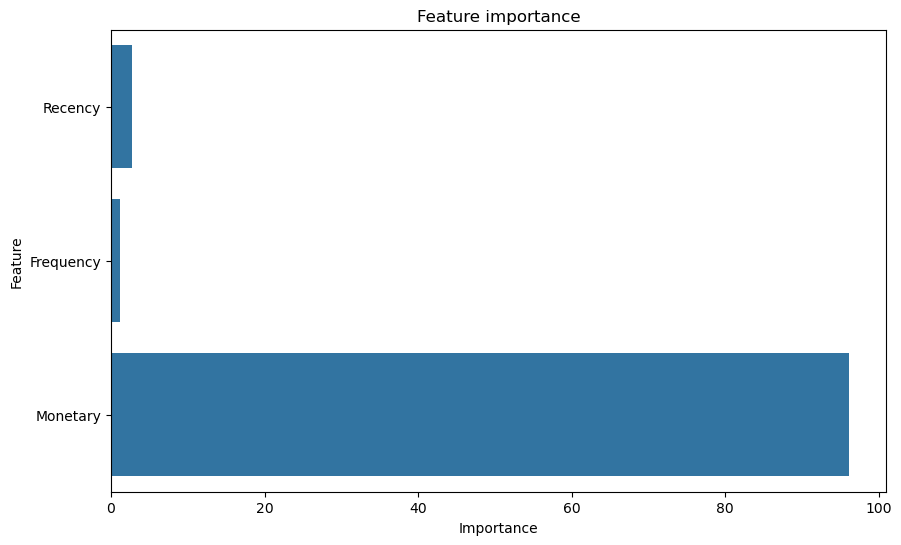

In [10]:
feature_importance  =model.get_feature_importance()
features = X.columns
importance_df = pd.DataFrame({'Feature':features, 'Importance':feature_importance})
plt.figure(figsize=(10,6))
sns.barplot(x ='Importance', y='Feature', data=importance_df)
plt.title('Feature importance')
plt.show()

**Step 8: Interactive GUI with ipywidgets**

In [11]:
import ipywidgets as widgets
from IPython.display import display
recency_input = widgets.IntSlider(min=0, max=365, step=1, description='Recency')
frequency_input = widgets.IntSlider(min=0, max=100, step=1, description='Frequency')
monetary_input = widgets.FloatSlider(min=0, max=10000, step=0.01, description='Monetary')

output = widgets.Output()
def make_prediction(recency, frequency, monetary):
    data = pd.DataFrame({'Recency':[recency], 'Frequency':[frequency], 'Monetary':[monetary]})
    prediction = model.predict(data)[0]
    return 'Recommend' if prediction == 1 else "Do not recomend"
def update_prediction(change):
    with output:
        output.clear_output()
        prediction = make_prediction(recency_input.value, frequency_input.value, monetary_input.value)
        print(f'Recommendation:{prediction}')
recency_input.observe(update_prediction, names='value')
frequency_input.observe(update_prediction, names='value')
monetary_input.observe(update_prediction, names='value')

display(recency_input, frequency_input, monetary_input, output)

IntSlider(value=0, description='Recency', max=365)

IntSlider(value=0, description='Frequency')

FloatSlider(value=0.0, description='Monetary', max=10000.0, step=0.01)

Output()